<a href="https://colab.research.google.com/github/priyanujgoswami09275-dotcom/App_dev_2026/blob/master/EDA_House_Pricing.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [9]:
from google.colab import files
uploaded = files.upload()



Saving train.csv to train (1).csv


# Exploratory Data Analysis of the Ames Housing Dataset

**Dataset:** House Prices: Advanced Regression Techniques (Kaggle), file `train.csv` (1,460 houses, 81 columns)
**Tools:** Python, Pandas, NumPy, Matplotlib, Seaborn
**Objective:** Use exploratory data analysis only (no machine learning) to understand which factors drive house sale prices.

## Guiding questions (written before touching the data)
1. How is `SalePrice` distributed? Is it skewed?
2. Which numerical features correlate most strongly with `SalePrice`?
3. Does overall quality (`OverallQual`) change price in a clear, ordered way?
4. Do some neighborhoods consistently cost more than others?
5. Are there outliers, and are they errors or real but unusual sales?
6. Which columns have missing values, and which of those are not truly missing?

# 2. Data Loading (Step 1)
**What I am about to do:** upload `train.csv`, import the libraries, and take a first look at the shape, data types and missing values.

In [10]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")

df = pd.read_csv("train.csv")
print(df.shape)
df.head()

(1460, 81)


,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


In [11]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1460 entries, 0 to 1459
Data columns (total 81 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             1460 non-null   int64  
 1   MSSubClass     1460 non-null   int64  
 2   MSZoning       1460 non-null   object 
 3   LotFrontage    1201 non-null   float64
 4   LotArea        1460 non-null   int64  
 5   Street         1460 non-null   object 
 6   Alley          91 non-null     object 
 7   LotShape       1460 non-null   object 
 8   LandContour    1460 non-null   object 
 9   Utilities      1460 non-null   object 
 10  LotConfig      1460 non-null   object 
 11  LandSlope      1460 non-null   object 
 12  Neighborhood   1460 non-null   object 
 13  Condition1     1460 non-null   object 
 14  Condition2     1460 non-null   object 
 15  BldgType       1460 non-null   object 
 16  HouseStyle     1460 non-null   object 
 17  OverallQual    1460 non-null   int64  
 18  OverallC

Missing Values


In [12]:
missing = df.isnull().sum().sort_values(ascending=False)
missing = missing[missing > 0]
missing_table = pd.DataFrame({
    "count": missing,
    "percent": (missing / len(df) * 100).round(1)
})
print("Columns with missing values:", len(missing_table))
missing_table

Columns with missing values: 19


,count,percent
PoolQC,1453,99.5
MiscFeature,1406,96.3
Alley,1369,93.8
Fence,1179,80.8
MasVnrType,872,59.7
FireplaceQu,690,47.3
LotFrontage,259,17.7
GarageQual,81,5.5
GarageFinish,81,5.5
GarageType,81,5.5


**What I learned (Step 1)**
- The dataset has **1,460 rows and 81 columns**.
- **19 columns** have missing values. The worst are `PoolQC` (99.5%), `MiscFeature` (96.3%), `Alley` (93.8%), `Fence` (80.8%), `MasVnrType` (59.7%) and `FireplaceQu` (47.3%). `LotFrontage` is missing in 17.7% of rows, the garage columns in 5.5% and the basement columns in about 2.5%.
- First impression: a house cannot have a pool quality unless it has a pool, so most of these gaps look like "feature absent", not "data lost". I will check this in the cleaning step (Question 6).
- Columns that share the same count (all 5 garage columns = 81, most basement columns = 37 or 38) suggest the same 81 houses have no garage and the same ~37 have no basement.

# 3. Data Understanding (Steps 2 and 3)
## Step 2: Classify variables
**What I am about to do:** split the columns into numeric and categorical, turn the quality columns into ordered (ordinal) categories, and build a summary table.

Classify Variables

In [13]:
numeric_cols = df.select_dtypes(include="number").columns.tolist()
categorical_cols = df.select_dtypes(include="object").columns.tolist()

print("Numeric columns:", len(numeric_cols))
print("Categorical columns:", len(categorical_cols))

Numeric columns: 38
Categorical columns: 43


Convert Ordinal Columns

In [14]:
order = ["Po", "Fa", "TA", "Gd", "Ex"]

for col in ["ExterQual", "KitchenQual"]:
    df[col] = pd.Categorical(df[col], categories=order, ordered=True)

print(df["ExterQual"].dtype)
df["ExterQual"].value_counts()

category


,count
ExterQual,
TA,906
Gd,488
Ex,52
Fa,14
Po,0


Summary Table

In [15]:
summary = pd.DataFrame({
    "column": df.columns,
    "type": [str(df[c].dtype) for c in df.columns],
    "unique_values": [df[c].nunique() for c in df.columns],
    "example_values": [df[c].dropna().unique()[:3].tolist() for c in df.columns]
})
summary

,column,type,unique_values,example_values
0,Id,int64,1460,"[1, 2, 3]"
1,MSSubClass,int64,15,"[60, 20, 70]"
2,MSZoning,object,5,"[RL, RM, C (all)]"
3,LotFrontage,float64,110,"[65.0, 80.0, 68.0]"
4,LotArea,int64,1073,"[8450, 9600, 11250]"
...,...,...,...,...
76,MoSold,int64,12,"[2, 5, 9]"
77,YrSold,int64,5,"[2008, 2007, 2006]"
78,SaleType,object,9,"[WD, New, COD]"
79,SaleCondition,object,6,"[Normal, Abnorml, Partial]"


## Step 3: Descriptive statistics
**What I am about to do:** summarise the centre and spread of `SalePrice`, `GrLivArea` and `LotArea`, and count the categories in `Neighborhood` and `HouseStyle`.

In [16]:
df[numeric_cols].describe().T

,count,mean,std,min,25%,50%,75%,max
Id,1460.0,730.500000,421.610009,1.0,365.75,730.5,1095.25,1460.0
MSSubClass,1460.0,56.897260,42.300571,20.0,20.00,50.0,70.00,190.0
LotFrontage,1201.0,70.049958,24.284752,21.0,59.00,69.0,80.00,313.0
LotArea,1460.0,10516.828082,9981.264932,1300.0,7553.50,9478.5,11601.50,215245.0
OverallQual,1460.0,6.099315,1.382997,1.0,5.00,6.0,7.00,10.0
OverallCond,1460.0,5.575342,1.112799,1.0,5.00,5.0,6.00,9.0
YearBuilt,1460.0,1971.267808,30.202904,1872.0,1954.00,1973.0,2000.00,2010.0
YearRemodAdd,1460.0,1984.865753,20.645407,1950.0,1967.00,1994.0,2004.00,2010.0
MasVnrArea,1452.0,103.685262,181.066207,0.0,0.00,0.0,166.00,1600.0
BsmtFinSF1,1460.0,443.639726,456.098091,0.0,0.00,383.5,712.25,5644.0


In [17]:
rows = {}
for c in ["SalePrice", "GrLivArea", "LotArea"]:
    s = df[c]
    rows[c] = {
        "mean": s.mean(),
        "median": s.median(),
        "mode": s.mode()[0],
        "std": s.std(),
        "variance": s.var(),
        "min": s.min(),
        "max": s.max(),
        "range": s.max() - s.min(),
        "IQR": s.quantile(0.75) - s.quantile(0.25),
        "skewness": s.skew(),
        "kurtosis": s.kurt(),
    }
stats_table = pd.DataFrame(rows).round(2)
display(stats_table)

for c in ["SalePrice", "GrLivArea", "LotArea"]:
    if df[c].mean() > df[c].median():
        print(c, "-> mean > median -> right skewed")
    elif df[c].mean() < df[c].median():
        print(c, "-> mean < median -> left skewed")
    else:
        print(c, "-> mean = median -> symmetric")

,SalePrice,GrLivArea,LotArea
mean,1.809212e+05,1515.46,10516.83
median,1.630000e+05,1464.00,9478.50
mode,1.400000e+05,864.00,7200.00
std,7.944250e+04,525.48,9981.26
variance,6.311111e+09,276129.63,99625649.65
min,3.490000e+04,334.00,1300.00
max,7.550000e+05,5642.00,215245.00
range,7.201000e+05,5308.00,213945.00
IQR,8.402500e+04,647.25,4048.00
skewness,1.880000e+00,1.37,12.21


SalePrice -> mean > median -> right skewed
GrLivArea -> mean > median -> right skewed
LotArea -> mean > median -> right skewed


In [18]:
for c in ["Neighborhood", "HouseStyle"]:
    print("-----", c, "-----")
    print(df[c].value_counts())
    print("Mode:", df[c].mode()[0])
    print()

----- Neighborhood -----
Neighborhood
NAmes      225
CollgCr    150
OldTown    113
Edwards    100
Somerst     86
Gilbert     79
NridgHt     77
Sawyer      74
NWAmes      73
SawyerW     59
BrkSide     58
Crawfor     51
Mitchel     49
NoRidge     41
Timber      38
IDOTRR      37
ClearCr     28
SWISU       25
StoneBr     25
Blmngtn     17
MeadowV     17
BrDale      16
Veenker     11
NPkVill      9
Blueste      2
Name: count, dtype: int64
Mode: NAmes

----- HouseStyle -----
HouseStyle
1Story    726
2Story    445
1.5Fin    154
SLvl       65
SFoyer     37
1.5Unf     14
2.5Unf     11
2.5Fin      8
Name: count, dtype: int64
Mode: 1Story



**What I learned (Step 3)**
- **SalePrice:** mean = $180,921 but median = $163,000, a gap of about **$17,900 (11%)**. Mean > median means a **right (positive) skew**: a few very expensive houses pull the mean up. Skewness is 1.88 and the maximum ($755,000) is far above the middle 50% range ($129,975 to $214,000).
- **GrLivArea** is also right skewed (mean 1,515 vs median 1,464, skewness 1.37).
- **LotArea** is extremely skewed (skewness 12.2, kurtosis 203). A few huge lots (up to 215,245 sq ft) exist next to a typical lot of about 9,500 sq ft, so I should be careful using its mean.
- The most common sale price is $140,000 (mode). The most common neighborhood is **NAmes (225 houses)** and about half the houses (726 of 1,460) are **1Story**.

# 4. Data Cleaning (Step 9)
**What I am about to do:** clean the data *before* the analysis, because missing values affect correlations and plots. I check duplicates, messy category labels, missing values that are not really missing, and impossible values.

I keep an untouched copy `df_raw` so I can always compare with the original.

In [19]:
df_raw = df.copy()

# 1. Duplicates
dup_count = df.duplicated().sum()
print("Duplicate rows:", dup_count)
if dup_count > 0:
    df = df.drop_duplicates()
    print("New shape:", df.shape)

Duplicate rows: 0


In [20]:
# 2. Inconsistent labels in text columns (casing, extra spaces)
text_cols = [c for c in categorical_cols if c not in ["ExterQual", "KitchenQual"]]

problems = []
for c in text_cols:
    values = df[c].dropna().astype(str)
    cleaned = values.str.strip().str.lower()
    if values.nunique() != cleaned.nunique():
        problems.append(c)

print("Columns with casing/space problems:", problems)

# Quick look at all labels of a few columns to spot similar spellings
for c in ["MSZoning", "Neighborhood", "Exterior2nd"]:
    print(c, sorted(df[c].dropna().unique()))

Columns with casing/space problems: []
MSZoning ['C (all)', 'FV', 'RH', 'RL', 'RM']
Neighborhood ['Blmngtn', 'Blueste', 'BrDale', 'BrkSide', 'ClearCr', 'CollgCr', 'Crawfor', 'Edwards', 'Gilbert', 'IDOTRR', 'MeadowV', 'Mitchel', 'NAmes', 'NPkVill', 'NWAmes', 'NoRidge', 'NridgHt', 'OldTown', 'SWISU', 'Sawyer', 'SawyerW', 'Somerst', 'StoneBr', 'Timber', 'Veenker']
Exterior2nd ['AsbShng', 'AsphShn', 'Brk Cmn', 'BrkFace', 'CBlock', 'CmentBd', 'HdBoard', 'ImStucc', 'MetalSd', 'Other', 'Plywood', 'Stone', 'Stucco', 'VinylSd', 'Wd Sdng', 'Wd Shng']


In [21]:
# 3. "Missing" values that really mean "feature absent"
# data_description.txt says NA = the house does not have this feature.
absent_cols = ["PoolQC", "MiscFeature", "Alley", "Fence", "FireplaceQu",
               "GarageType", "GarageFinish", "GarageQual", "GarageCond",
               "BsmtQual", "BsmtCond", "BsmtExposure", "BsmtFinType1", "BsmtFinType2",
               "MasVnrType"]

before = df[absent_cols].isnull().sum()
df[absent_cols] = df[absent_cols].fillna("None")
print("Filled with 'None':")
print(before[before > 0])

Filled with 'None':
PoolQC          1453
MiscFeature     1406
Alley           1369
Fence           1179
FireplaceQu      690
GarageType        81
GarageFinish      81
GarageQual        81
GarageCond        81
BsmtQual          37
BsmtCond          37
BsmtExposure      38
BsmtFinType1      37
BsmtFinType2      38
MasVnrType       872
dtype: int64


In [22]:
# 4. Numeric columns with real gaps
print("Missing before:")
print(df.isnull().sum()[df.isnull().sum() > 0])

# LotFrontage: median of the same neighborhood (similar streets have similar frontage)
df["LotFrontage"] = df.groupby("Neighborhood")["LotFrontage"].transform(lambda s: s.fillna(s.median()))

# MasVnrArea: no veneer -> area is 0
df["MasVnrArea"] = df["MasVnrArea"].fillna(0)

# GarageYrBlt: no garage -> use the year the house was built (0 would ruin averages and correlations)
df["GarageYrBlt"] = df["GarageYrBlt"].fillna(df["YearBuilt"])

# Electrical: only 1 missing value -> fill with the most common value
df["Electrical"] = df["Electrical"].fillna(df["Electrical"].mode()[0])

print()
print("Missing after:", df.isnull().sum().sum())

Missing before:
LotFrontage    259
MasVnrArea       8
Electrical       1
GarageYrBlt     81
dtype: int64

Missing after: 0


In [23]:
# 5. Impossible values
print("Sold before it was built:", (df["YearBuilt"] > df["YrSold"]).sum())
print("Remodelled before it was built:", (df["YearRemodAdd"] < df["YearBuilt"]).sum())
print("Garage built after sale:", (df["GarageYrBlt"] > df["YrSold"]).sum())
print("Remodel year after sale year:", (df["YearRemodAdd"] > df["YrSold"]).sum())

area_cols = [c for c in df.columns if "Area" in c or "SF" in c]
print("Negative areas:", (df[area_cols] < 0).sum().sum())

Sold before it was built: 0
Remodelled before it was built: 0
Garage built after sale: 0
Remodel year after sale year: 1
Negative areas: 0


**What I learned (Step 9: cleaning)**
- **Duplicates:** none. **Inconsistent labels:** none (no casing or extra-space problems).
- **Missing values that are not really missing:** I filled 15 columns with `"None"` (`PoolQC`, `MiscFeature`, `Alley`, `Fence`, `FireplaceQu`, 4 garage columns, 5 basement columns, `MasVnrType`) because `data_description.txt` says NA means the house has no such feature. This answers Question 6.
- Note: `MasVnrType` showed 872 missing, but 864 of those are the real text value "None" (no masonry veneer), which pandas reads as NaN by default. Only 8 were truly missing.
- **Real gaps, my decisions:**
  - `LotFrontage` (259): median of the same neighborhood, because streets in one area have similar frontage.
  - `MasVnrArea` (8): set to 0 (no veneer).
  - `GarageYrBlt` (81): set to `YearBuilt`. Using 0 would wreck averages and correlations.
  - `Electrical` (1): most common value (`SBrkr`).
- Missing values left: **0**.
- **Impossible values:** none (no house sold before it was built, no negative areas). One house (Id 524) was remodelled in 2008 but sold in 2007, probably a planned remodel. I keep it for now.

# 5. Univariate Analysis (Step 4)
**What I am about to do:** look at the shape of `SalePrice`, test whether a log transform fixes its skew, and see how price differs by quality and neighborhood.

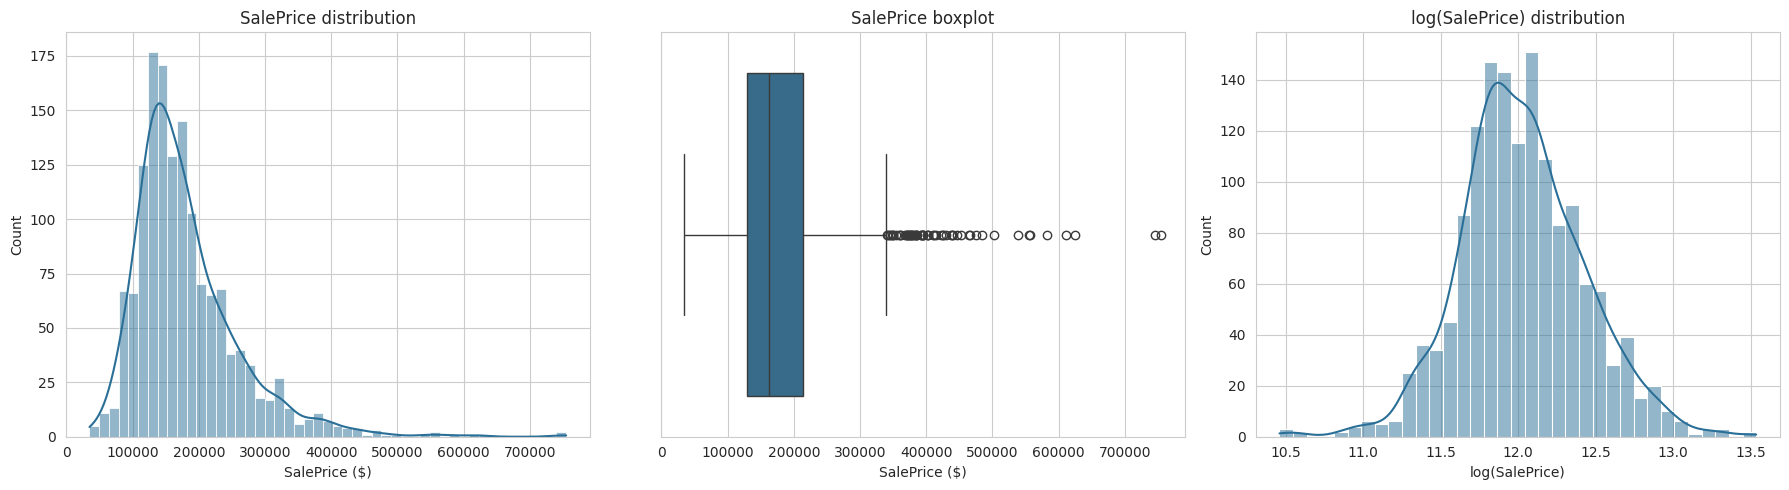

Skewness of SalePrice      : 1.883
Skewness of log(SalePrice) : 0.121


In [24]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

sns.histplot(df["SalePrice"], kde=True, ax=axes[0], color="#2a6f97")
axes[0].set_title("SalePrice distribution")
axes[0].set_xlabel("SalePrice ($)")
axes[0].set_ylabel("Count")

sns.boxplot(x=df["SalePrice"], ax=axes[1], color="#2a6f97")
axes[1].set_title("SalePrice boxplot")
axes[1].set_xlabel("SalePrice ($)")

sns.histplot(np.log(df["SalePrice"]), kde=True, ax=axes[2], color="#2a6f97")
axes[2].set_title("log(SalePrice) distribution")
axes[2].set_xlabel("log(SalePrice)")
axes[2].set_ylabel("Count")

plt.tight_layout()
plt.show()

print("Skewness of SalePrice      :", round(df["SalePrice"].skew(), 3))
print("Skewness of log(SalePrice) :", round(np.log(df["SalePrice"]).skew(), 3))

**What I learned (Question 1)**
- `SalePrice` is clearly **right skewed** (skewness 1.88): the histogram has a long right tail and the boxplot shows many dots on the high side.
- After the log transform the skewness drops to **0.12**, so `log(SalePrice)` is close to a normal bell shape. This confirms the first expected insight.

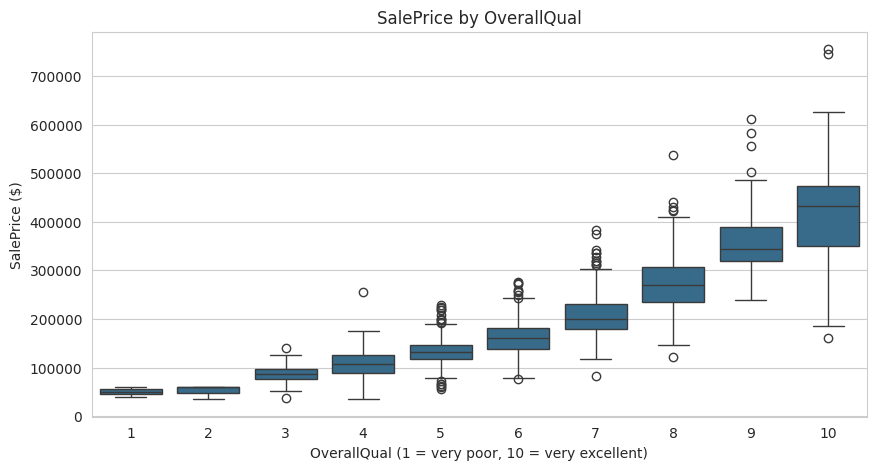

,SalePrice
OverallQual,
1,50150.0
2,60000.0
3,86250.0
4,108000.0
5,133000.0
6,160000.0
7,200141.0
8,269750.0
9,345000.0


In [25]:
plt.figure(figsize=(10, 5))
sns.boxplot(data=df, x="OverallQual", y="SalePrice", color="#2a6f97")
plt.title("SalePrice by OverallQual")
plt.xlabel("OverallQual (1 = very poor, 10 = very excellent)")
plt.ylabel("SalePrice ($)")
plt.show()

# median price per quality level
df.groupby("OverallQual")["SalePrice"].median()

**What I learned (Question 3)**
- Median price rises with every quality level, from $50,150 (quality 1) to $108,000 (4), $160,000 (6), $269,750 (8) and **$432,390 (10)**. So yes, quality changes price in a clear, ordered way.
- The spread also grows with quality (standard deviation about $27,000 at quality 5 vs about $160,000 at quality 10), so top-quality houses vary a lot in price.
- Most houses are quality 5 to 7 (1,090 of 1,460, about 75%). Quality 1 and 2 have only 2 and 3 houses, so those boxes are not reliable.

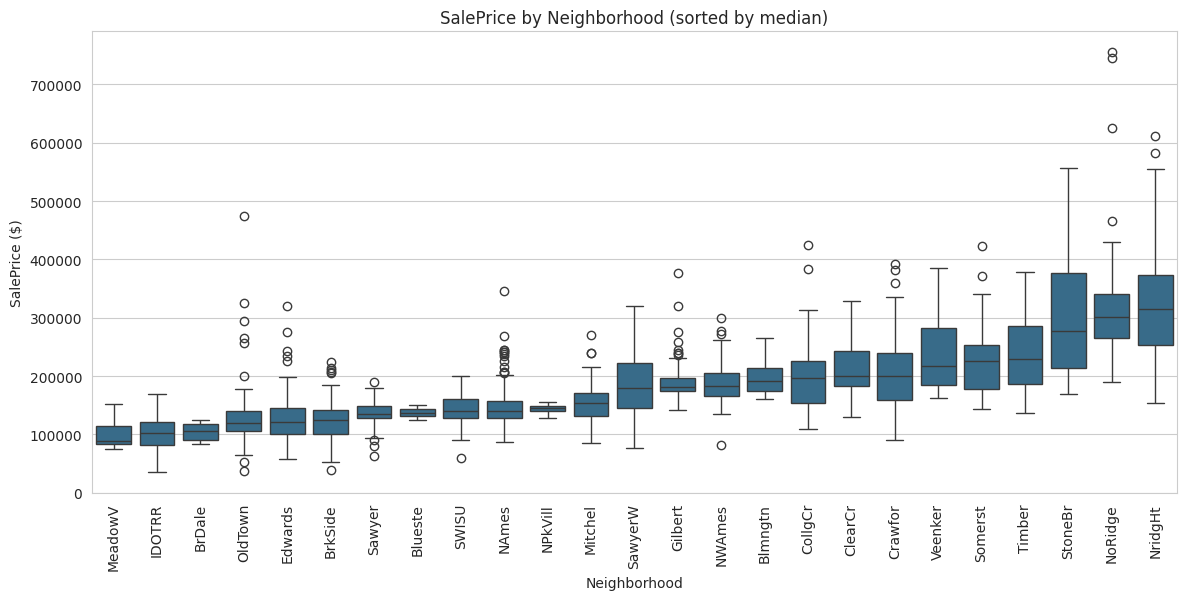

,SalePrice
Neighborhood,
NridgHt,315000.0
NoRidge,301500.0
StoneBr,278000.0
Timber,228475.0
Somerst,225500.0


In [26]:
nb_order = df.groupby("Neighborhood")["SalePrice"].median().sort_values().index

plt.figure(figsize=(14, 6))
sns.boxplot(data=df, x="Neighborhood", y="SalePrice", order=nb_order, color="#2a6f97")
plt.xticks(rotation=90)
plt.title("SalePrice by Neighborhood (sorted by median)")
plt.xlabel("Neighborhood")
plt.ylabel("SalePrice ($)")
plt.show()

df.groupby("Neighborhood")["SalePrice"].median().sort_values(ascending=False).head(5)

**What I learned (Question 4)**
- Yes, some neighborhoods are consistently more expensive. The highest medians are **NridgHt ($315,000), NoRidge ($301,500) and StoneBr ($278,000)**. The cheapest are **MeadowV ($88,000), IDOTRR ($103,000) and BrDale ($106,000)**.
- This is consistent, not a few lucky sales: 76 of 77 NridgHt houses (98.7%) and all 41 NoRidge and all 25 StoneBr houses sold above the overall median price of $163,000.
- Caution: small neighborhoods (for example Blueste with only 2 houses) have too few sales to judge.

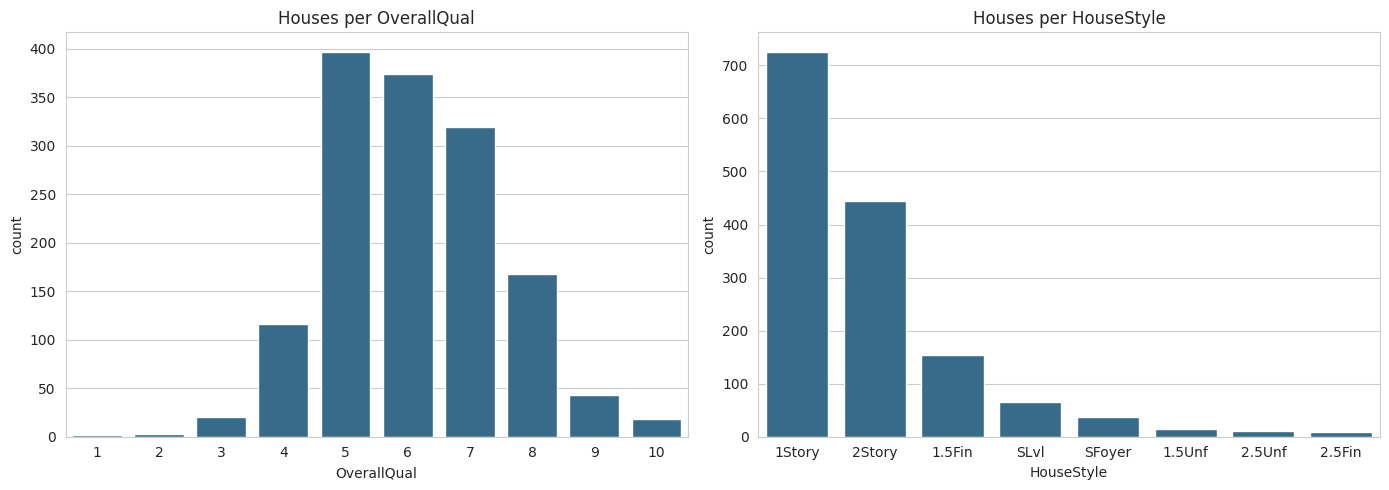

In [27]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.countplot(data=df, x="OverallQual", ax=axes[0], color="#2a6f97")
axes[0].set_title("Houses per OverallQual")

sns.countplot(data=df, x="HouseStyle", ax=axes[1], color="#2a6f97",
              order=df["HouseStyle"].value_counts().index)
axes[1].set_title("Houses per HouseStyle")

plt.tight_layout()
plt.show()

**What I learned (countplots)**

- `OverallQual`: most houses are quality 5, 6 or 7 (397, 374 and 319 houses, 1,090 of 1,460, about 75%). Very few houses are at the extremes (only 5 houses at quality 1 or 2, and 18 at quality 10).
- `HouseStyle`: `1Story` (726) and `2Story` (445) make up 1,171 of 1,460 houses, about 80% of the data.

# 6. Bivariate and Multivariate Analysis (Steps 5, 6, 7)
## Step 5: Correlation and covariance
**What I am about to do:** find which numeric features move most with `SalePrice`.

In [28]:
num_df = df[numeric_cols]

cov_matrix = num_df.cov()
corr_matrix = num_df.corr(method="pearson")

top_corr = corr_matrix["SalePrice"].drop("SalePrice").abs().sort_values(ascending=False)
top10 = top_corr.head(10).index.tolist()

print("Top 10 features correlated with SalePrice:")
corr_matrix.loc[top10, "SalePrice"].round(3)

Top 10 features correlated with SalePrice:


,SalePrice
OverallQual,0.791
GrLivArea,0.709
GarageCars,0.640
GarageArea,0.623
TotalBsmtSF,0.614
1stFlrSF,0.606
FullBath,0.561
TotRmsAbvGrd,0.534
YearBuilt,0.523
GarageYrBlt,0.508


In [29]:
for f in top10[:3]:
    print(f"{f:12s} covariance with SalePrice = {cov_matrix.loc[f, 'SalePrice']:>16,.0f}   correlation = {corr_matrix.loc[f, 'SalePrice']:.3f}")

OverallQual  covariance with SalePrice =           86,904   correlation = 0.791
GrLivArea    covariance with SalePrice =       29,581,867   correlation = 0.709
GarageCars   covariance with SalePrice =           38,020   correlation = 0.640


In [30]:
# Optional: Spearman (rank) correlation, better for ordinal-like columns
spearman = num_df.corr(method="spearman")["SalePrice"].drop("SalePrice")
spearman.abs().sort_values(ascending=False).head(10).round(3)

,SalePrice
OverallQual,0.810
GrLivArea,0.731
GarageCars,0.691
YearBuilt,0.653
GarageArea,0.649
FullBath,0.636
GarageYrBlt,0.613
TotalBsmtSF,0.603
1stFlrSF,0.575
YearRemodAdd,0.571


In [31]:
# Two features that are correlated with each other
print("GarageArea vs GarageCars:", round(df["GarageArea"].corr(df["GarageCars"]), 3))
print("GrLivArea vs TotRmsAbvGrd:", round(df["GrLivArea"].corr(df["TotRmsAbvGrd"]), 3))
print("TotalBsmtSF vs 1stFlrSF:", round(df["TotalBsmtSF"].corr(df["1stFlrSF"]), 3))

GarageArea vs GarageCars: 0.882
GrLivArea vs TotRmsAbvGrd: 0.825
TotalBsmtSF vs 1stFlrSF: 0.82


**What I learned (Question 2, Step 5)**
- Top 10 correlations with `SalePrice`: `OverallQual` **0.79**, `GrLivArea` **0.71**, `GarageCars` 0.64, `GarageArea` 0.62, `TotalBsmtSF` 0.61, `1stFlrSF` 0.61, `FullBath` 0.56, `TotRmsAbvGrd` 0.53, `YearBuilt` 0.52, `GarageYrBlt` 0.51. This confirms the second expected insight: quality and living area lead.
- **Covariance vs correlation:** the covariances are 86,904 (`OverallQual`), 29,581,867 (`GrLivArea`) and 38,020 (`GarageCars`). They depend on the units of each column, so I cannot compare them. Correlation is covariance divided by both standard deviations, so it is always between -1 and 1 and directly comparable.
- **Spearman (rank) correlation** gives similar results; `YearBuilt` jumps from 0.52 to 0.65, so its link with price is more steady-increasing than a straight line.
- **Correlation is not causation.** `GarageArea` and `GarageCars` are correlated at **0.88** with each other, so they carry almost the same information. Also `GrLivArea` vs `TotRmsAbvGrd` is 0.83 and `TotalBsmtSF` vs `1stFlrSF` is 0.82. This matters because we cannot tell which one "drives" price, and in a later model such pairs would be redundant. A garage does not create value by itself: bigger, better houses simply tend to have bigger garages.

## Step 6: Scatter plots and pair plots
**What I am about to do:** plot the main numeric features against price and mark the unusual points.

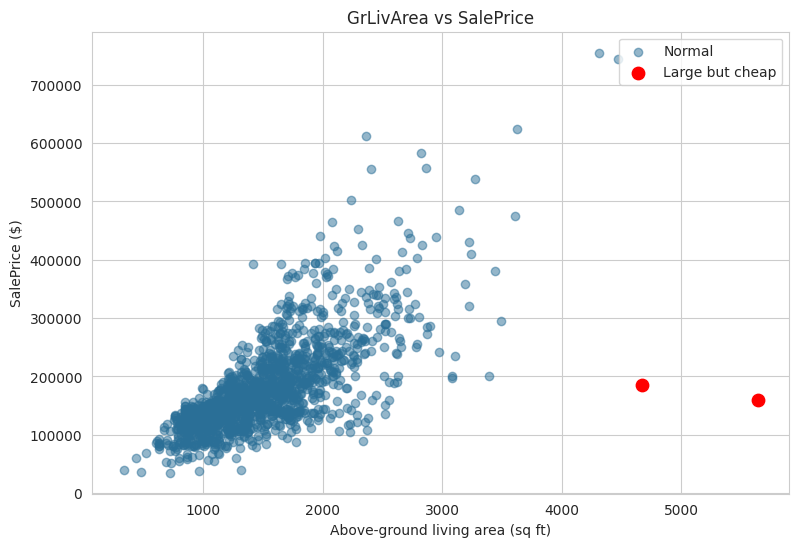

,Id,GrLivArea,SalePrice,OverallQual,Neighborhood,SaleCondition
523,524,4676,184750,10,Edwards,Partial
1298,1299,5642,160000,10,Edwards,Partial


In [32]:
flag = (df["GrLivArea"] > 4000) & (df["SalePrice"] < 300000)

plt.figure(figsize=(9, 6))
plt.scatter(df.loc[~flag, "GrLivArea"], df.loc[~flag, "SalePrice"], alpha=0.5, color="#2a6f97", label="Normal")
plt.scatter(df.loc[flag, "GrLivArea"], df.loc[flag, "SalePrice"], color="red", s=80, label="Large but cheap")
plt.title("GrLivArea vs SalePrice")
plt.xlabel("Above-ground living area (sq ft)")
plt.ylabel("SalePrice ($)")
plt.legend()
plt.show()

df.loc[flag, ["Id", "GrLivArea", "SalePrice", "OverallQual", "Neighborhood", "SaleCondition"]]

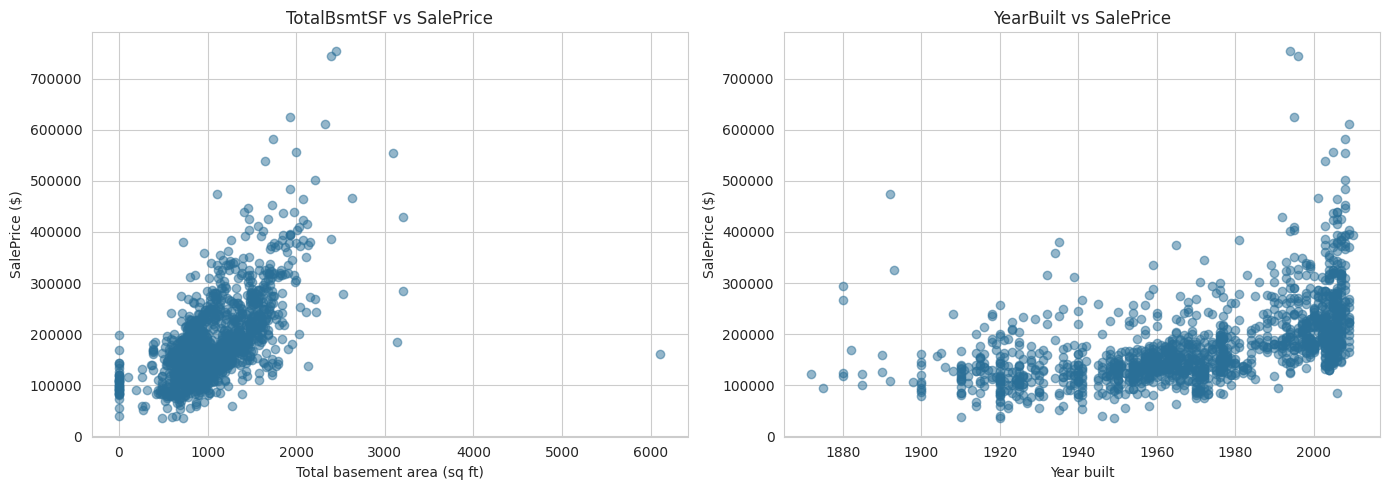

In [33]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].scatter(df["TotalBsmtSF"], df["SalePrice"], alpha=0.5, color="#2a6f97")
axes[0].set_title("TotalBsmtSF vs SalePrice")
axes[0].set_xlabel("Total basement area (sq ft)")
axes[0].set_ylabel("SalePrice ($)")

axes[1].scatter(df["YearBuilt"], df["SalePrice"], alpha=0.5, color="#2a6f97")
axes[1].set_title("YearBuilt vs SalePrice")
axes[1].set_xlabel("Year built")
axes[1].set_ylabel("SalePrice ($)")

plt.tight_layout()
plt.show()

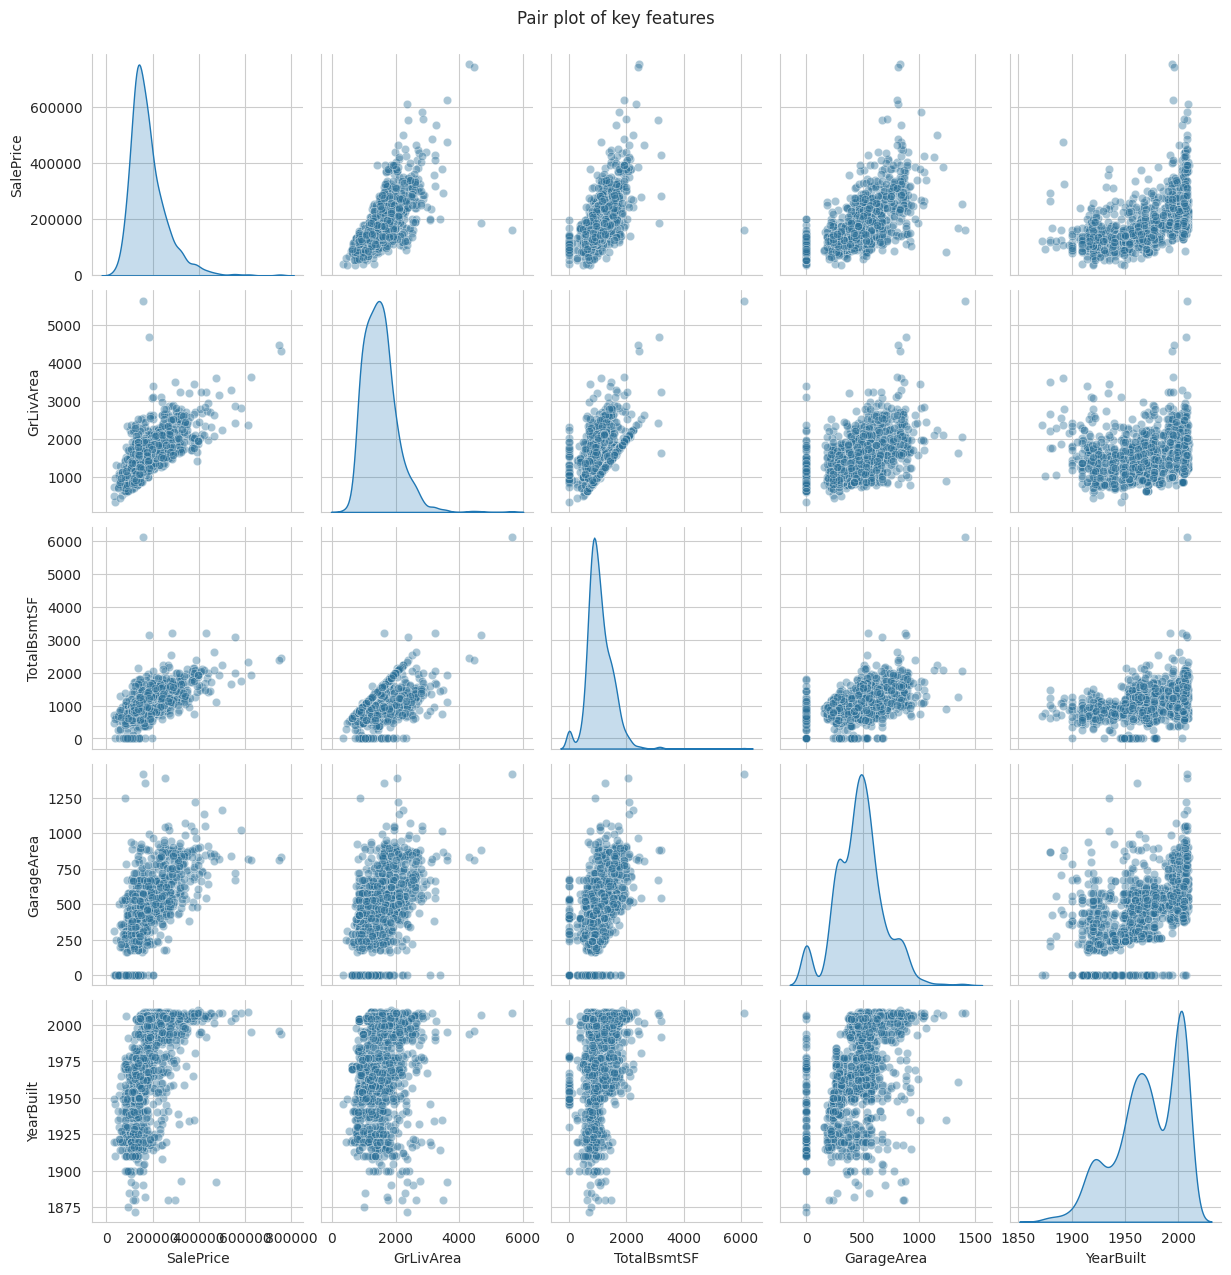

In [34]:
selected = ["SalePrice", "GrLivArea", "TotalBsmtSF", "GarageArea", "YearBuilt"]
sns.pairplot(df[selected], diag_kind="kde", plot_kws={"alpha": 0.4, "color": "#2a6f97"})
plt.suptitle("Pair plot of key features", y=1.02)
plt.show()

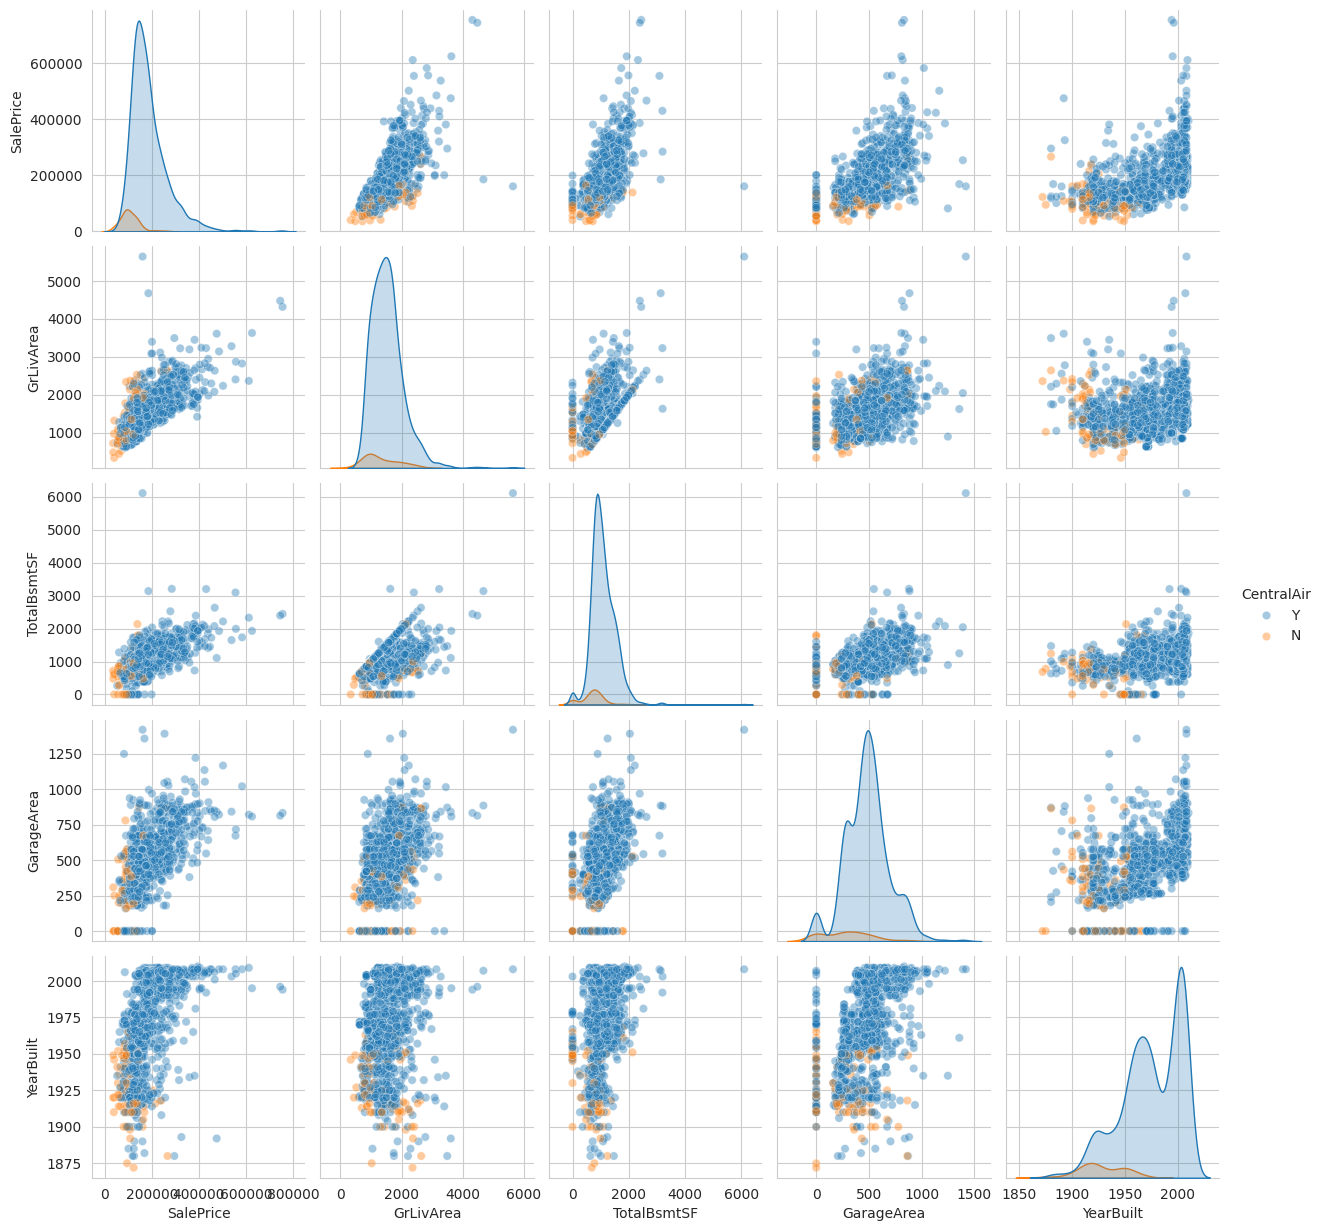

In [35]:
# Optional: colour by a categorical column
sns.pairplot(df[selected + ["CentralAir"]], hue="CentralAir", diag_kind="kde", plot_kws={"alpha": 0.4})
plt.show()

**What I learned (Step 6)**
- `GrLivArea` vs `SalePrice` is a clear upward trend. Two red points break it: **Id 524 (4,676 sq ft, $184,750) and Id 1299 (5,642 sq ft, $160,000)**. Both are in Edwards, both are quality 10, and both have `SaleCondition = Partial` (sold before the house was completed). They are big but cheap, so they look like unusual sales, not normal market prices.
- The two other houses above 4,000 sq ft (Ids 692 and 1183) sold for $755,000 and $745,000, which fits the trend, so they are real.
- `TotalBsmtSF` shows the same pattern (the 6,110 sq ft basement belongs to Id 1299). `YearBuilt`: newer houses cost more (average $238,675 for houses built after 1990 vs $155,878 for 1951 to 1990 and $132,019 up to 1950), and prices vary more among the newer houses (standard deviation about $86,000 vs about $47,000 to $53,000).
- The scatter plots widen like a fan: bigger houses have more price spread.
- Pair plot: `GrLivArea`, `TotalBsmtSF` and `GarageArea` all rise with price, and the KDEs on the diagonal are right skewed. With `CentralAir` colouring, the 95 houses without central air are much cheaper (median $98,000 vs $168,000) and much older (median built 1925 vs 1976).

## Step 7: Correlation heatmap
**What I am about to do:** draw one clear picture of how the 10 strongest features relate to price and to each other.

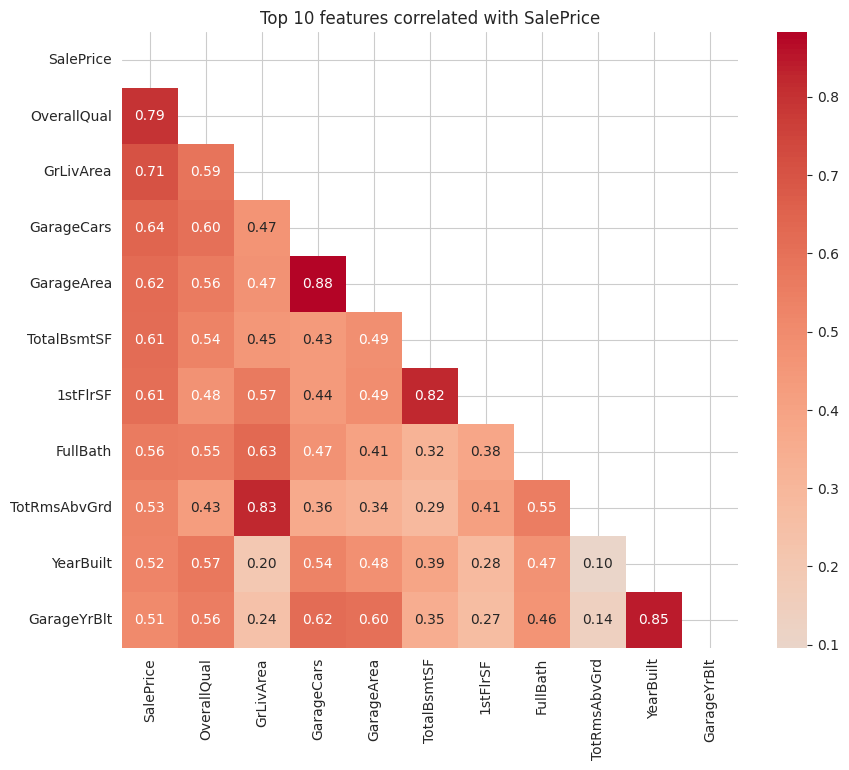

In [36]:
cols = ["SalePrice"] + top10
corr_top = df[cols].corr()
mask = np.triu(np.ones_like(corr_top, dtype=bool))

plt.figure(figsize=(10, 8))
sns.heatmap(corr_top, annot=True, fmt=".2f", cmap="coolwarm", center=0, mask=mask, square=True)
plt.title("Top 10 features correlated with SalePrice")
plt.show()

**What I learned (Step 7)**
- `OverallQual` has the strongest link with price (0.79).
- The heatmap also shows clusters of features that overlap: `GarageCars`/`GarageArea` (0.88), `YearBuilt`/`GarageYrBlt` (0.85), `GrLivArea`/`TotRmsAbvGrd` (0.83) and `TotalBsmtSF`/`1stFlrSF` (0.82). These are different ways of measuring the same thing (garage size, age, house size, ground-floor size).
- All ten features are positively correlated with price, so the heatmap is mostly red.

# 7. Outlier Analysis (Step 8)
**What I am about to do:** detect outliers with two methods (IQR and z-score), compare them, and decide whether to remove or keep them.

In [37]:
def iqr_outliers(series):
    q1 = series.quantile(0.25)
    q3 = series.quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    return series[(series < lower) | (series > upper)]

def zscore_outliers(series, threshold=3):
    z = (series - series.mean()) / series.std()
    return series[z.abs() > threshold]

for c in ["GrLivArea", "SalePrice"]:
    a = iqr_outliers(df[c])
    b = zscore_outliers(df[c])
    overlap = a.index.intersection(b.index)
    print(f"{c}: IQR flags {len(a)}, z-score flags {len(b)}, overlap {len(overlap)}")

GrLivArea: IQR flags 31, z-score flags 16, overlap 16
SalePrice: IQR flags 61, z-score flags 22, overlap 22


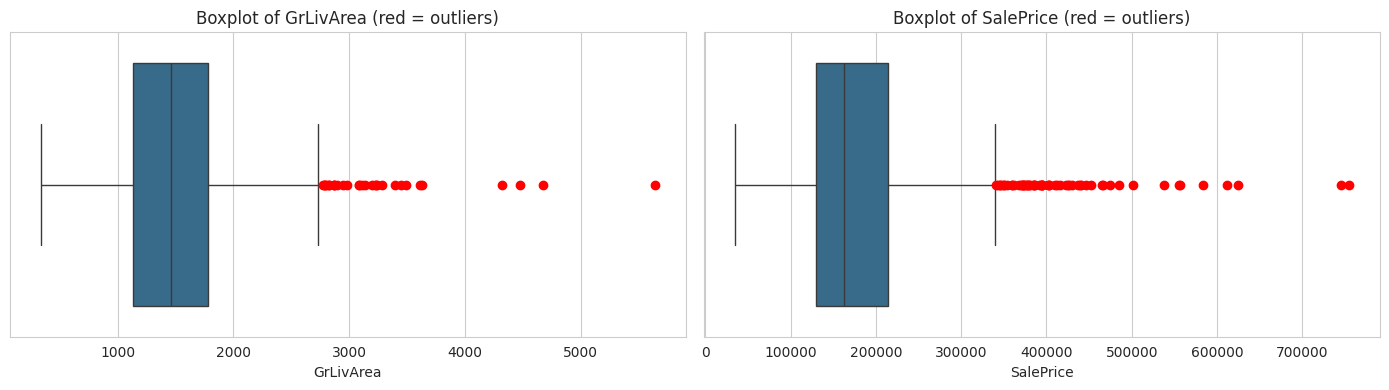

In [38]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for ax, c in zip(axes, ["GrLivArea", "SalePrice"]):
    sns.boxplot(x=df[c], ax=ax, color="#2a6f97", flierprops={"markerfacecolor": "red", "markeredgecolor": "red"})
    ax.set_title(f"Boxplot of {c} (red = outliers)")
plt.tight_layout()
plt.show()

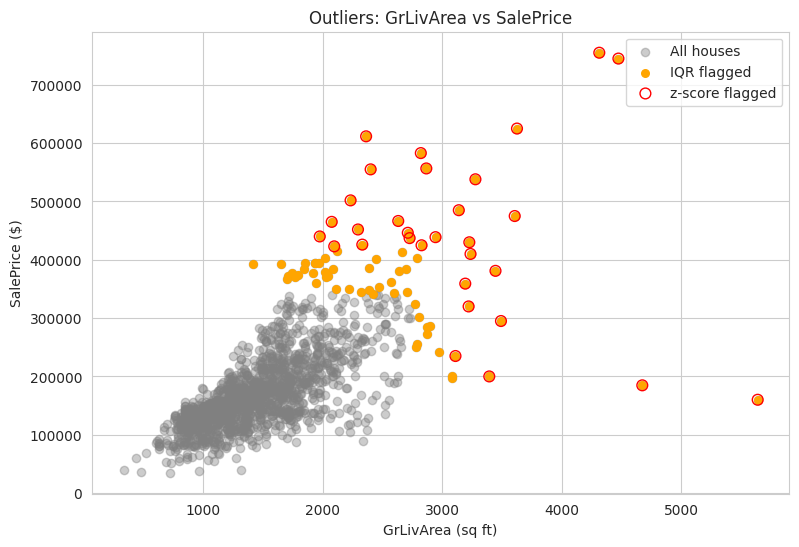

In [39]:
iqr_idx = iqr_outliers(df["GrLivArea"]).index.union(iqr_outliers(df["SalePrice"]).index)
z_idx = zscore_outliers(df["GrLivArea"]).index.union(zscore_outliers(df["SalePrice"]).index)

plt.figure(figsize=(9, 6))
plt.scatter(df["GrLivArea"], df["SalePrice"], alpha=0.4, color="grey", label="All houses")
plt.scatter(df.loc[iqr_idx, "GrLivArea"], df.loc[iqr_idx, "SalePrice"], color="orange", s=30, label="IQR flagged")
plt.scatter(df.loc[z_idx, "GrLivArea"], df.loc[z_idx, "SalePrice"], color="red", s=60, facecolors="none", label="z-score flagged")
plt.title("Outliers: GrLivArea vs SalePrice")
plt.xlabel("GrLivArea (sq ft)")
plt.ylabel("SalePrice ($)")
plt.legend()
plt.show()

In [40]:
# Decision: remove only the houses that are very large AND cheap (non-typical sales)
bad = (df["GrLivArea"] > 4000) & (df["SalePrice"] < 300000)
print(df.loc[bad, ["Id", "GrLivArea", "SalePrice", "SaleCondition"]])

df_clean = df[~bad].copy()
print("Shape before:", df.shape, " after:", df_clean.shape)

print("Correlation GrLivArea-SalePrice before:", round(df["GrLivArea"].corr(df["SalePrice"]), 3))
print("Correlation GrLivArea-SalePrice after :", round(df_clean["GrLivArea"].corr(df_clean["SalePrice"]), 3))

        Id  GrLivArea  SalePrice SaleCondition
523    524       4676     184750       Partial
1298  1299       5642     160000       Partial
Shape before: (1460, 81)  after: (1458, 81)
Correlation GrLivArea-SalePrice before: 0.709
Correlation GrLivArea-SalePrice after : 0.735


**What I learned (Question 5, Step 8)**
- **GrLivArea:** IQR flags 31 houses, z-score flags 16, and all 16 z-score points are also in the IQR set. **SalePrice:** IQR flags 61, z-score flags 22 (overlap 22).
- **Why z-score flags fewer on skewed data:** the mean and standard deviation are themselves pulled up by the long right tail, so `mean + 3*std` is a high bar ($419,249 for `SalePrice`). The IQR fence uses quartiles, which ignore extremes, so it sits lower ($340,038). Same for `GrLivArea` (3,092 vs 2,748).
- **Decision:** I removed only the **2 houses** (Id 524 and 1299) that are very large and very cheap and were `Partial` sales. They are non-typical sales, not market prices. This creates `df_clean` (1,458 rows) and the correlation of `GrLivArea` with `SalePrice` rises from **0.709 to 0.735**, which shows they were distorting the trend.
- I **kept** all the expensive outliers: for example the $755,000 and $745,000 houses are real, high-quality sales, and removing them would hide the true top of the market.

# 8. Dashboard (Step 10)
**What I am about to do:** combine the best four visuals into one figure and save it as `eda_dashboard.png`. I use `df_clean` so the two unusual sales do not distort the picture.

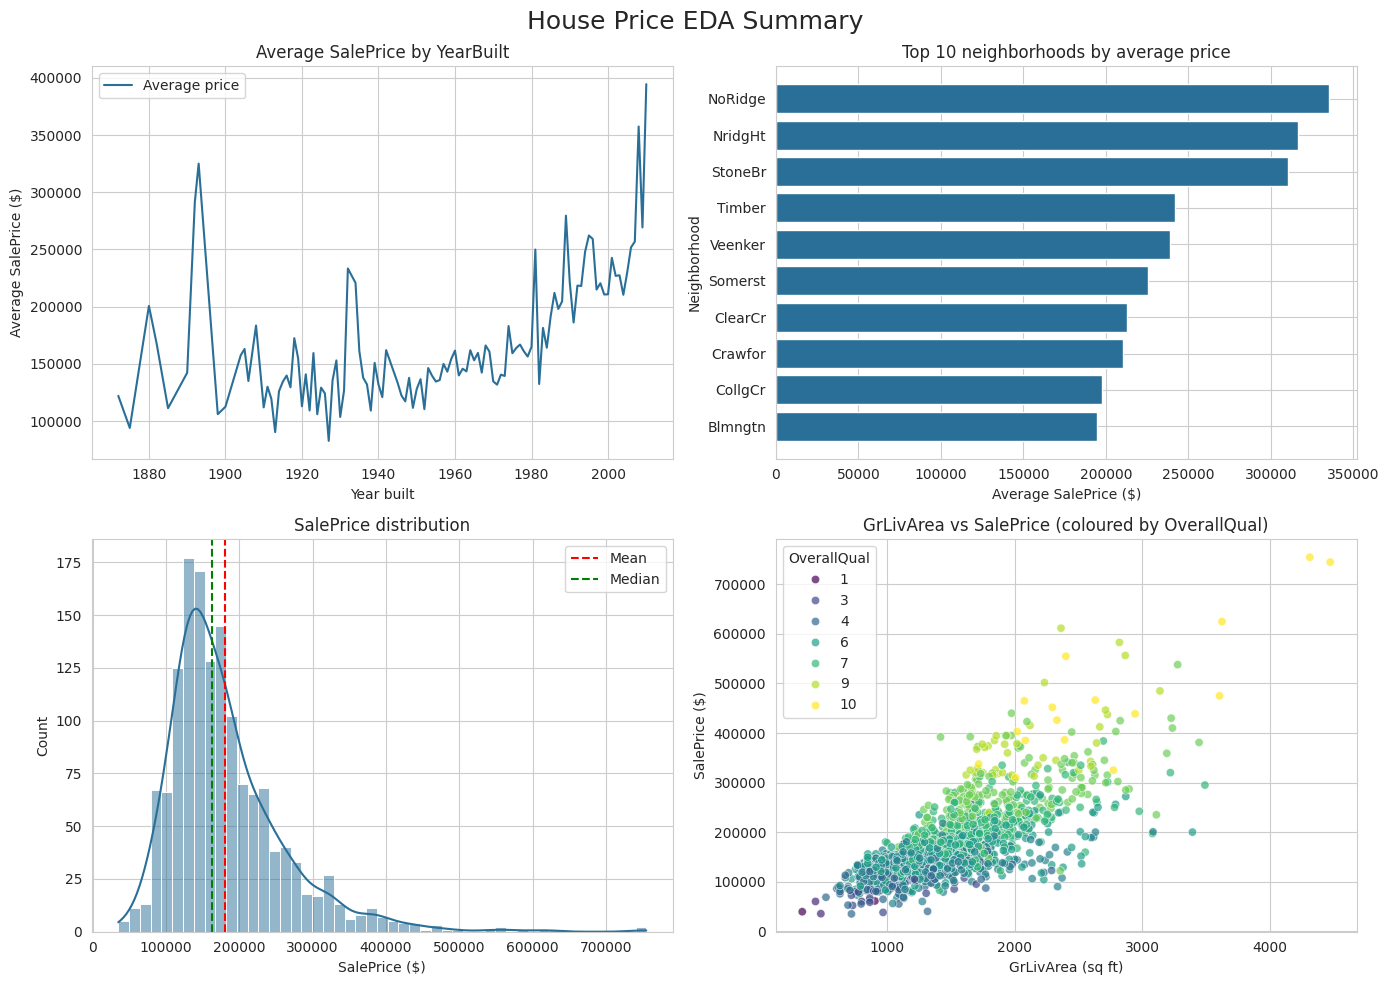

In [41]:
main_color = "#2a6f97"
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Panel 1: average price by year built
avg_by_year = df_clean.groupby("YearBuilt")["SalePrice"].mean()
axes[0, 0].plot(avg_by_year.index, avg_by_year.values, color=main_color, label="Average price")
axes[0, 0].set_title("Average SalePrice by YearBuilt")
axes[0, 0].set_xlabel("Year built")
axes[0, 0].set_ylabel("Average SalePrice ($)")
axes[0, 0].legend()

# Panel 2: top 10 neighborhoods
top_nb = df_clean.groupby("Neighborhood")["SalePrice"].mean().sort_values(ascending=False).head(10)
axes[0, 1].barh(top_nb.index[::-1], top_nb.values[::-1], color=main_color)
axes[0, 1].set_title("Top 10 neighborhoods by average price")
axes[0, 1].set_xlabel("Average SalePrice ($)")
axes[0, 1].set_ylabel("Neighborhood")

# Panel 3: distribution with mean and median
sns.histplot(df_clean["SalePrice"], kde=True, color=main_color, ax=axes[1, 0])
axes[1, 0].axvline(df_clean["SalePrice"].mean(), color="red", linestyle="--", label="Mean")
axes[1, 0].axvline(df_clean["SalePrice"].median(), color="green", linestyle="--", label="Median")
axes[1, 0].set_title("SalePrice distribution")
axes[1, 0].set_xlabel("SalePrice ($)")
axes[1, 0].set_ylabel("Count")
axes[1, 0].legend()

# Panel 4: GrLivArea vs SalePrice coloured by quality
sns.scatterplot(data=df_clean, x="GrLivArea", y="SalePrice", hue="OverallQual",
                palette="viridis", alpha=0.7, ax=axes[1, 1])
axes[1, 1].set_title("GrLivArea vs SalePrice (coloured by OverallQual)")
axes[1, 1].set_xlabel("GrLivArea (sq ft)")
axes[1, 1].set_ylabel("SalePrice ($)")

fig.suptitle("House Price EDA Summary", fontsize=18)
plt.tight_layout()
plt.savefig("eda_dashboard.png", dpi=150, bbox_inches="tight")
plt.show()

**What I learned (Step 10: dashboard)**
- Average price by year built is noisy for old years (few houses) but trends upward, with the clearest rise for houses built after about 1990.
- By average price the top three neighborhoods are **NoRidge ($335,295), NridgHt ($316,271) and StoneBr ($310,499)**.
- The mean (red line) sits to the right of the median (green line), showing the right skew again.
- In the scatter plot, colour moves from dark purple to yellow as price goes up, so price depends on **both size and quality together**: at the same `GrLivArea`, the higher-quality houses cost more.

In [42]:
from google.colab import files
files.download("eda_dashboard.png")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

# 9. Conclusions

## Answers to my guiding questions
1. **Distribution of SalePrice:** right skewed (skewness 1.88, mean $180,921 > median $163,000). A log transform reduces skewness to 0.12, close to normal.
2. **Strongest numeric correlates:** `OverallQual` (0.79), `GrLivArea` (0.71), `GarageCars` (0.64), `GarageArea` (0.62), `TotalBsmtSF` (0.61).
3. **OverallQual and price:** price rises steadily with quality (median $50,150 at quality 1 to $432,390 at quality 10), with a much larger spread at the top.
4. **Neighborhoods:** yes. NridgHt, NoRidge and StoneBr have clearly higher medians ($278,000 to $315,000) than the cheapest ones (MeadowV, IDOTRR, BrDale: $88,000 to $106,000).
5. **Outliers:** 2 houses (Id 524 and 1299) were very large but cheap `Partial` sales, so I removed them. The other flagged points are real expensive houses and were kept.
6. **Missing values:** 19 columns had gaps, but most (pool, alley, fence, fireplace, garage, basement, masonry veneer) mean "feature absent" and were filled with `"None"`, not dropped. Only `LotFrontage`, `MasVnrArea`, `GarageYrBlt` and `Electrical` were real gaps.

## Expected insights: verified
| Expected insight | Result |
|---|---|
| SalePrice is right skewed, log makes it near normal | Confirmed (1.88 to 0.12) |
| OverallQual and GrLivArea are the strongest correlates | Confirmed (0.79 and 0.71) |
| Price rises steadily with quality, bigger spread at top | Confirmed |
| A few neighborhoods have clearly higher medians | Confirmed |
| A handful of very large, low-priced houses are unusual sales | Confirmed (2 houses, both Partial sales) |
| Many "missing" values are really "feature absent" | Confirmed (15 columns) |

## Limitations
- The data covers one city (Ames, Iowa) from 2006 to 2010, so the findings may not apply elsewhere or today.
- Correlation is not causation, and many features overlap (for example `GarageCars` and `GarageArea`).
- Pearson correlation only measures straight-line relationships.
- My imputation choices (neighborhood median, `YearBuilt` for `GarageYrBlt`) are assumptions and could be done differently.
- `Id` and `MSSubClass` were treated as numbers in the correlation matrix even though they are labels.
- Some neighborhoods and quality levels have very few houses, so their statistics are less reliable.
- This is EDA only. No predictive model was built.